# AliceText: Comparing RNN, Bidirectional RNN, LSTM and GRU
## ICT4403 — Foundations of Generative AI, Assignment 2

**Status:** Ready to run; no experimental results have been pre-filled.

Predict the next word from a fixed-length context, then generate text autoregressively. Compare four recurrent architectures under a shared training protocol.

### Before running
1. Upload this notebook to Google Colab and save a copy in Drive.
2. Select **Runtime → Change runtime type → GPU** (if available).
3. Run cells in order. Approve the Drive mount to persist checkpoints and outputs.
4. Download the results ZIP at the end, and download the executed notebook separately.

A quick smoke test is available below. Use `QUICK_RUN = False` for the actual experiment. A quick run is not a final result.

Dataset: Lewis Carroll, *Alice’s Adventures in Wonderland*, Project Gutenberg ebook 11.
Source: https://www.gutenberg.org/ebooks/11
Plain text: https://www.gutenberg.org/ebooks/11.txt.utf-8

We remove Gutenberg boilerplate and the table of contents, lowercase words and retain internal apostrophes. Punctuation is excluded, so fluency is judged at word level; punctuation quality is not evaluated.


In [3]:
import os, re, json, time, math, hashlib, platform, shutil
from pathlib import Path
from collections import Counter
from urllib.request import urlopen
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from IPython.display import display

QUICK_RUN = False
USE_DRIVE = False
SEED = 42
CONTEXT = 20
EMBED_DIM = 64
HIDDEN_UNITS = 128
BATCH_SIZE = 128
EPOCHS = 2 if QUICK_RUN else 20
LEARNING_RATE = 0.001
TEMPERATURES = [0.5, 1.0, 1.5]
GENERATION_LENGTH = 60
REPEATS = 3
MODEL_NAMES = ['SimpleRNN', 'BidirectionalRNN', 'LSTM', 'GRU']

if USE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    ROOT = Path('/content/drive/MyDrive/FGAI_Assignment2')
else:
    ROOT = Path.cwd() / 'FGAI_Assignment2'
ROOT = ROOT / ('quick_run' if QUICK_RUN else 'full_run')
for sub in ['data', 'models', 'results', 'plots']:
    (ROOT / sub).mkdir(parents=True, exist_ok=True)
tf.keras.utils.set_random_seed(SEED)
try:
    tf.config.experimental.enable_op_determinism()
except AttributeError:
    pass
print('TensorFlow:', tf.__version__)
print('GPU:', tf.config.list_physical_devices('GPU'))
print('Output folder:', ROOT)


TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Output folder: /content/FGAI_Assignment2/full_run


## 1. Download and prepare the dataset
The file is cached in Drive. If the download is unavailable, download the plain-text file from the source page and place it at `data/alice_raw.txt` in the output folder, then rerun this cell.

We use the first 80% of word tokens for training, the next 10% for validation and the final 10% for testing. Splitting **before** window creation prevents overlapping windows from crossing splits. This chronological split also tests generalization to later narrative passages. Vocabulary is fitted on training text only; unseen words map to `<unk>`.


In [4]:
DATA_URL = 'https://www.gutenberg.org/ebooks/11.txt.utf-8'
raw_path = ROOT / 'data/alice_raw.txt'
if not raw_path.exists():
    with urlopen(DATA_URL, timeout=60) as response:
        raw_path.write_bytes(response.read())
raw = raw_path.read_text(encoding='utf-8-sig')
start = re.search(r'\*\*\* START OF .*?\*\*\*', raw, flags=re.I)
end = re.search(r'\*\*\* END OF .*?\*\*\*', raw, flags=re.I)
assert start and end, 'Gutenberg markers missing; inspect the downloaded file.'
body = raw[start.end():end.start()]
opening = re.search(r'Alice was beginning to get very tired', body, flags=re.I)
assert opening, 'Could not find the opening paragraph.'
body = body[opening.start():]
# Remove chapter labels and titles (the first chapter heading is already removed).
body = re.sub(r'(?im)^\s*CHAPTER\s+[IVXLCDM]+\.?[^\n]*\n', '\n', body)
body = body.replace('’', "'").replace('‘', "'")
def tokenize(text):
    return re.findall(r"[a-z]+(?:'[a-z]+)*", text.lower().replace('’', "'").replace('‘', "'"))
words = tokenize(body)
assert len(words) > 10000, 'Unexpectedly short dataset.'
a, b = int(len(words)*0.8), int(len(words)*0.9)
parts = {'train': words[:a], 'validation': words[a:b], 'test': words[b:]}
counts = Counter(parts['train'])
vocab = ['<pad>', '<unk>'] + sorted(counts, key=lambda w: (-counts[w], w))
word_to_id = {w:i for i,w in enumerate(vocab)}
V = len(vocab)
ids = {k: np.array([word_to_id.get(w, 1) for w in ws], dtype=np.int32) for k,ws in parts.items()}
if QUICK_RUN:
    ids = {k: v[:min(len(v), 2500 if k == 'train' else 600)] for k,v in ids.items()}
(ROOT/'data/vocabulary.json').write_text(json.dumps(vocab, indent=2))
(ROOT/'data/cleaned_text.txt').write_text(' '.join(words))
stats = pd.DataFrame([{'split': k, 'words_used': len(v), 'sequences': len(v)-CONTEXT,
                        'unknown_fraction': float(np.mean(v == 1))} for k,v in ids.items()])
stats.to_csv(ROOT/'results/dataset_stats.csv', index=False)
print('Full cleaned corpus words:', len(words), '| Training vocabulary:', V)
display(stats)
print('Opening:', ' '.join(words[:60]))


Full cleaned corpus words: 26661 | Training vocabulary: 2317


,split,words_used,sequences,unknown_fraction
0,train,21328,21308,0.000000
1,validation,2666,2646,0.086272
2,test,2667,2647,0.085489


Opening: alice was beginning to get very tired of sitting by her sister on the bank and of having nothing to do once or twice she had peeped into the book her sister was reading but it had no pictures or conversations in it and what is the use of a book thought alice without pictures or conversations so she was


## 2. Construct input–target pairs
For context length 20, each example has 20 preceding words as input and the 21st word as target. Slide the window forward by one word. Targets are integer IDs, so sparse categorical cross-entropy avoids large one-hot matrices.

The bidirectional model processes the **observed 20-word context** in both directions. It never receives the target word or future words beyond the context, so next-word prediction remains valid.


In [5]:
def make_xy(arr):
    windows = np.lib.stride_tricks.sliding_window_view(arr, CONTEXT + 1)
    return windows[:, :-1].copy(), windows[:, -1].copy()
xy = {k: make_xy(v) for k,v in ids.items()}
def dataset(split, training=False):
    x,y = xy[split]
    ds = tf.data.Dataset.from_tensor_slices((x,y))
    if training:
        ds = ds.shuffle(len(x), seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
print('Example input:', ' '.join(vocab[i] for i in xy['train'][0][0]))
print('Target:', vocab[xy['train'][1][0]])
for k,(x,y) in xy.items():
    assert x.shape == (len(y), CONTEXT)
    assert x.max() < V and y.max() < V


Example input: alice was beginning to get very tired of sitting by her sister on the bank and of having nothing to
Target: do


## 3. Comparable model definitions
Every model uses a 64-dimensional embedding, one recurrent layer, dropout 0.2 and a vocabulary-sized output layer producing logits. Each has 128 recurrent units **per direction**; the bidirectional model therefore has more parameters. We report counts rather than claim equal capacity.

Training uses Adam (learning rate 0.001, gradient clipping 1.0), batch size 128, the same maximum of 20 epochs, and early stopping with patience 3 on validation loss. The best validation checkpoint is evaluated. Equal training policy does not imply equal epochs or compute.

- **Simple RNN:** recurrent hidden state with tanh; baseline for short-range dependencies.
- **Bidirectional Simple RNN:** forward and backward Simple RNNs over the available context.
- **LSTM:** input, forget and output gates plus a cell state.
- **GRU:** update and reset gates with a simpler gated state.


In [6]:
def build_model(name):
    inputs = tf.keras.Input(shape=(CONTEXT,), dtype='int32')
    x = tf.keras.layers.Embedding(V, EMBED_DIM)(inputs)
    if name == 'SimpleRNN':
        x = tf.keras.layers.SimpleRNN(HIDDEN_UNITS)(x)
    elif name == 'BidirectionalRNN':
        x = tf.keras.layers.Bidirectional(tf.keras.layers.SimpleRNN(HIDDEN_UNITS))(x)
    elif name == 'LSTM':
        x = tf.keras.layers.LSTM(HIDDEN_UNITS)(x)
    elif name == 'GRU':
        x = tf.keras.layers.GRU(HIDDEN_UNITS)(x)
    else:
        raise ValueError(name)
    x = tf.keras.layers.Dropout(0.2)(x)
    logits = tf.keras.layers.Dense(V)(x)
    model = tf.keras.Model(inputs, logits, name=name)
    model.compile(optimizer=tf.keras.optimizers.Adam(LEARNING_RATE, clipnorm=1.0),
                  loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
                  metrics=[tf.keras.metrics.SparseCategoricalAccuracy(name='accuracy')])
    return model

config = dict(seed=SEED, context=CONTEXT, embedding=EMBED_DIM, hidden_units=HIDDEN_UNITS,
              batch_size=BATCH_SIZE, max_epochs=EPOCHS, learning_rate=LEARNING_RATE,
              quick_run=QUICK_RUN, dataset_url=DATA_URL,
              dataset_sha256=hashlib.sha256(raw_path.read_bytes()).hexdigest(),
              tensorflow=tf.__version__, numpy=np.__version__, python=platform.python_version())
config_path = ROOT/'config.json'
if config_path.exists():
    assert json.loads(config_path.read_text()) == config, (
        'Configuration changed. Use a new ROOT folder to avoid mixing experiments.')
else:
    config_path.write_text(json.dumps(config, indent=2))
print(json.dumps(config, indent=2))


{
  "seed": 42,
  "context": 20,
  "embedding": 64,
  "hidden_units": 128,
  "batch_size": 128,
  "max_epochs": 20,
  "learning_rate": 0.001,
  "quick_run": false,
  "dataset_url": "https://www.gutenberg.org/ebooks/11.txt.utf-8",
  "dataset_sha256": "01b38ea4c710a84bc18d0bd41271a5a1a92b94e97b2812f4dece97d4a694725e",
  "tensorflow": "2.21.0",
  "numpy": "2.1.3",
  "python": "3.13.15"
}


## 4. Train and evaluate
This is the main training cell. Completed models are reused after a reconnect. An interrupted model restarts training with the fixed seed; completed models are not retrained. To intentionally rerun the whole experiment, use a new output folder.

Training time includes the fit call, validation, tracing and checkpoint I/O, but excludes model construction, test evaluation and generation. Drive write latency and hardware affect it. One training seed is used; small differences should not be treated as statistically conclusive.

Test cross-entropy is the mean negative log probability of the target word. **Perplexity = exp(test loss)**; lower is better. Accuracy is the fraction of correct top-1 next-word predictions. Unknown targets remain in these metrics; inspect the unknown fractions when interpreting results.


In [7]:
rows = []
for name in MODEL_NAMES:
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)
    checkpoint = ROOT / f'models/{name}.keras'
    record = ROOT / f'results/{name}_metrics.json'
    if record.exists() and checkpoint.exists():
        rows.append(json.loads(record.read_text()))
        print('Reusing completed experiment:', name)
        continue
    model = build_model(name)
    callbacks = [
        tf.keras.callbacks.ModelCheckpoint(str(checkpoint), monitor='val_loss', save_best_only=True),
        tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True),
        tf.keras.callbacks.CSVLogger(str(ROOT / f'results/{name}_history.csv')),
        tf.keras.callbacks.TerminateOnNaN()
    ]
    print('Training', name, '| Parameters:', model.count_params())
    t0 = time.perf_counter()
    history = model.fit(dataset('train', True), validation_data=dataset('validation'),
                        epochs=EPOCHS, callbacks=callbacks, verbose=2)
    seconds = time.perf_counter() - t0
    model = tf.keras.models.load_model(checkpoint)
    val = model.evaluate(dataset('validation'), verbose=0, return_dict=True)
    test = model.evaluate(dataset('test'), verbose=0, return_dict=True)
    assert math.isfinite(test['loss']), 'Non-finite loss: inspect training.'
    result = dict(model=name, parameters=model.count_params(), epochs=len(history.history['loss']),
                  best_epoch=int(np.argmin(history.history['val_loss'])+1),
                  training_seconds=seconds, validation_loss=float(val['loss']),
                  test_loss=float(test['loss']), test_perplexity=float(np.exp(test['loss'])),
                  test_accuracy=float(test['accuracy']))
    record.write_text(json.dumps(result, indent=2))
    rows.append(result)
results = pd.DataFrame(rows)
results.to_csv(ROOT/'results/model_comparison.csv', index=False)
display(results.round(4))
# Validation selects the preferred model; test results are reported after selection.
selected = results.loc[results.validation_loss.idxmin(), 'model']
print('Lowest-validation-loss model:', selected)


Training SimpleRNN | Parameters: 471885
Epoch 1/20
167/167 - 11s - 66ms/step - accuracy: 0.0490 - loss: 6.3300 - val_accuracy: 0.0828 - val_loss: 6.2451
Epoch 2/20
167/167 - 4s - 25ms/step - accuracy: 0.0579 - loss: 5.9873 - val_accuracy: 0.0941 - val_loss: 6.0946
Epoch 3/20
167/167 - 4s - 25ms/step - accuracy: 0.0675 - loss: 5.7641 - val_accuracy: 0.0967 - val_loss: 6.0027
Epoch 4/20
167/167 - 4s - 25ms/step - accuracy: 0.0787 - loss: 5.5472 - val_accuracy: 0.1032 - val_loss: 5.9117
Epoch 5/20
167/167 - 5s - 31ms/step - accuracy: 0.1027 - loss: 5.3046 - val_accuracy: 0.1126 - val_loss: 5.8170
Epoch 6/20
167/167 - 4s - 25ms/step - accuracy: 0.1245 - loss: 5.0702 - val_accuracy: 0.1183 - val_loss: 5.7737
Epoch 7/20
167/167 - 4s - 25ms/step - accuracy: 0.1408 - loss: 4.8553 - val_accuracy: 0.1243 - val_loss: 5.7570
Epoch 8/20
167/167 - 4s - 25ms/step - accuracy: 0.1537 - loss: 4.6666 - val_accuracy: 0.1277 - val_loss: 5.7787
Epoch 9/20
167/167 - 4s - 25ms/step - accuracy: 0.1659 - loss: 

,model,parameters,epochs,best_epoch,training_seconds,validation_loss,test_loss,test_perplexity,test_accuracy
0,SimpleRNN,471885,10,7,52.0406,5.7570,5.8946,363.0890,0.1133
1,BidirectionalRNN,793165,6,3,49.8191,5.9294,6.0358,418.1172,0.0892
2,LSTM,545997,17,14,27.4130,5.9195,6.0581,427.5775,0.1179
3,GRU,521677,9,6,13.7905,5.6887,5.7896,326.8875,0.1300


Lowest-validation-loss model: GRU


## 5. Plot learning curves and model comparison
Training loss decreasing while validation loss rises suggests overfitting. Compare the best validation checkpoints rather than only the last epoch.


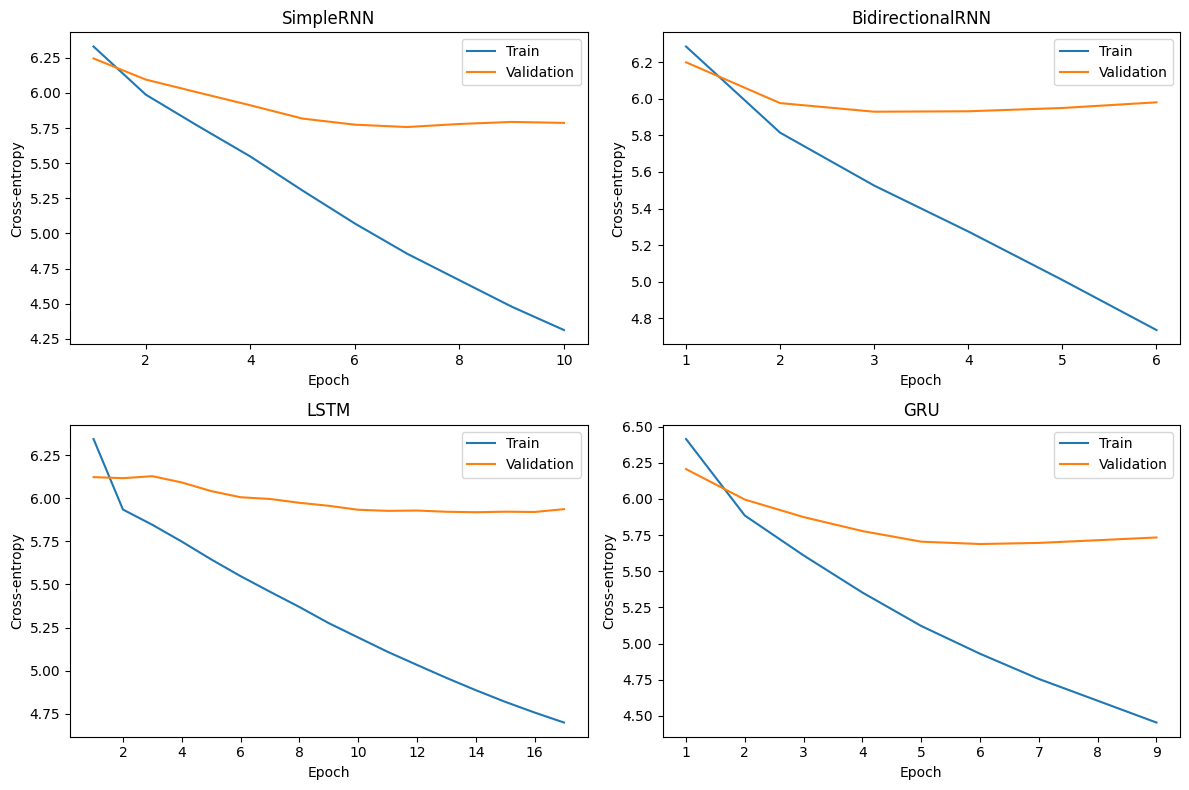

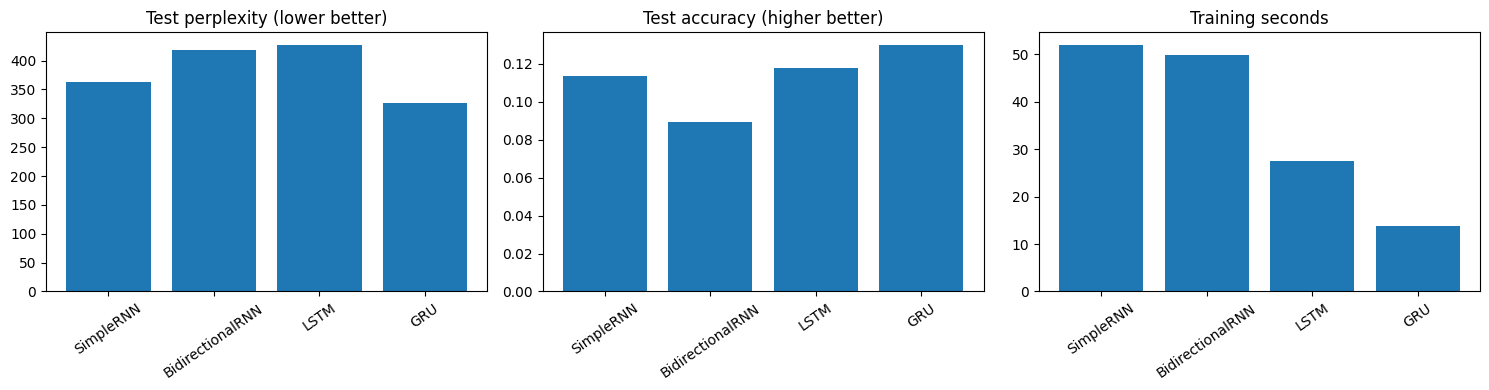

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax,name in zip(axes.flat, MODEL_NAMES):
    h = pd.read_csv(ROOT/f'results/{name}_history.csv')
    ax.plot(h.epoch+1, h.loss, label='Train')
    ax.plot(h.epoch+1, h.val_loss, label='Validation')
    ax.set(title=name, xlabel='Epoch', ylabel='Cross-entropy')
    ax.legend()
fig.tight_layout()
fig.savefig(ROOT/'plots/learning_curves.png', dpi=160)
plt.show()
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax,col,title in zip(axes, ['test_perplexity','test_accuracy','training_seconds'],
                       ['Test perplexity (lower better)', 'Test accuracy (higher better)', 'Training seconds']):
    ax.bar(results.model, results[col])
    ax.set_title(title)
    ax.tick_params(axis='x', rotation=35)
fig.tight_layout()
fig.savefig(ROOT/'plots/model_comparison.png', dpi=160)
plt.show()


## 6. Autoregressive generation at three temperatures
Temperature rescales logits: `p(word) = softmax(logits / T)`. Lower temperatures concentrate probability on likely words; higher temperatures spread it. Their actual effect must be assessed from the outputs, not assumed.

Each of 4 models uses the same 3 seeds, 3 temperatures and 3 random sampling repetitions: **108 continuations**, each 60 words long. No top-k filtering is applied. PAD and UNK are excluded only during generation; evaluation uses the original full distribution. Each step uses the most recent 20 words.

Distinct-1/2 are the number of unique unigrams/bigrams divided by their total counts. Repeated-bigram fraction is `1 - distinct-2`. These are diversity/repetition proxies, not measures of coherence. Compute them on generated words only, excluding the prompt.


Generated samples for SimpleRNN
Generated samples for BidirectionalRNN
Generated samples for LSTM
Generated samples for GRU


distinct_1        distinct_2         \
                                   mean    std       mean    std   
model            temperature                                       
BidirectionalRNN 0.5              0.546  0.062      0.885  0.042   
                 1.0              0.839  0.037      0.996  0.007   
                 1.5              0.933  0.022      1.000  0.000   
GRU              0.5              0.574  0.046      0.879  0.041   
                 1.0              0.813  0.037      0.987  0.016   
                 1.5              0.944  0.032      1.000  0.000   
LSTM             0.5              0.557  0.053      0.868  0.052   
                 1.0              0.800  0.028      0.989  0.012   
                 1.5              0.939  0.037      0.998  0.006   
SimpleRNN        0.5              0.574  0.083      0.887  0.083   
                 1.0              0.798  0.049      0.992  0.012   
                 1.5              0.944  0.034      1.000  0.000   

                             repeated_bigram_fraction         
                                                 mean    std  
model            temperature                                  
BidirectionalRNN 0.5                            0.115  0.042  
                 1.0                            0.004  0.007  
                 1.5                            0.000  0.000  
GRU              0.5                            0.121  0.041  
                 1.0                            0.013  0.016  
                 1.5                            0.000  0.000  
LSTM             0.5                            0.132  0.052  
                 1.0                            0.011  0.012  
                 1.5                            0.002  0.006  
SimpleRNN        0.5                            0.113  0.083  
                 1.0                            0.008  0.012  
                 1.5                            0.000  0.000


SimpleRNN | T=0.5
the mouse of this time i don't know it said the caterpillar and she had not been to the right turtle at the pigeon is that i can't get you see the dodo said the duchess if she might have a little small said the gryphon and the rabbit said alice and she went on the queen but she was


SimpleRNN | T=1.0
the duchess there myself would begun that said the door there must be round everything i afraid to what just being impossible and wink perhaps would kept law growing grown i'm you ah for i know crept a picture hole so she felt on i am i do me at least as that they rather again and morning did down


SimpleRNN | T=1.5
the hatter always solid attended bark do what got me saying new half love expecting its chatte to have hurried ancient happened to twist passing shaped try maybe lay sure dry up below looking too mock uncommonly one roughly every three to choked that asked broken is said that that arrow were body tasted muttered alice very raw shouldn't expecting


Bidirect

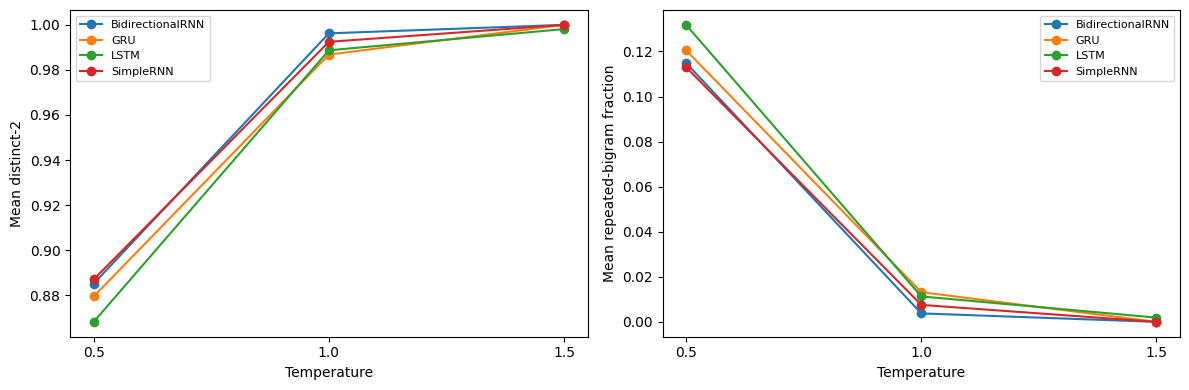

In [9]:
# Use three observed training contexts; never use test text as a prompt.
seed_positions = [0, len(parts['train'])//3, 2*len(parts['train'])//3]
seed_texts = [' '.join(parts['train'][i:i+CONTEXT]) for i in seed_positions]
(ROOT/'results/seeds.json').write_text(json.dumps(seed_texts, indent=2))

def generate(model, seed, temperature, rng_seed):
    assert temperature > 0
    context = [word_to_id.get(w, 1) for w in tokenize(seed)]
    assert len(context) >= CONTEXT
    rng = np.random.default_rng(rng_seed)
    output = []
    for _ in range(GENERATION_LENGTH):
        logits = model(np.array([context[-CONTEXT:]], dtype=np.int32), training=False).numpy()[0].astype('float64')
        logits[:2] = -np.inf
        logits = logits / temperature
        probs = np.exp(logits - np.max(logits))
        probs /= probs.sum()
        idx = int(rng.choice(V, p=probs))
        context.append(idx)
        output.append(vocab[idx])
    return output

def diversity(tokens):
    bigrams = list(zip(tokens, tokens[1:]))
    d1 = len(set(tokens))/len(tokens)
    d2 = len(set(bigrams))/len(bigrams)
    return dict(distinct_1=d1, distinct_2=d2, repeated_bigram_fraction=1-d2)

samples = []
for name in MODEL_NAMES:
    tf.keras.backend.clear_session()
    model = tf.keras.models.load_model(ROOT/f'models/{name}.keras')
    for seed_id,seed in enumerate(seed_texts, 1):
        for temp in TEMPERATURES:
            for rep in range(REPEATS):
                # Same RNG seeds across models and temperatures for comparability.
                rng_seed = SEED + seed_id*100 + rep
                output = generate(model, seed, temp, rng_seed)
                samples.append(dict(model=name, seed_id=seed_id, seed=seed, temperature=temp,
                                    repetition=rep+1, rng_seed=rng_seed,
                                    generated_text=' '.join(output), **diversity(output)))
    print('Generated samples for', name)
samples = pd.DataFrame(samples)
samples.to_csv(ROOT/'results/generated_samples.csv', index=False)
summary = samples.groupby(['model','temperature'])[['distinct_1','distinct_2','repeated_bigram_fraction']].agg(['mean','std'])
summary.to_csv(ROOT/'results/temperature_summary.csv')
display(summary.round(3))
text_report = '\n\n'.join(
    f"MODEL: {r.model} | T={r.temperature} | Seed {r.seed_id} | Repeat {r.repetition}\nPROMPT: {r.seed}\nCONTINUATION: {r.generated_text}"
    for r in samples.itertuples())
(ROOT/'results/generated_samples.txt').write_text(text_report)
for r in samples[(samples.seed_id == 1) & (samples.repetition == 1)].itertuples():
    print(f'\n{r.model} | T={r.temperature}\n{r.generated_text}\n')
fig, axes = plt.subplots(1,2, figsize=(12,4))
means = samples.groupby(['model','temperature'], as_index=False)[['distinct_2','repeated_bigram_fraction']].mean()
for name,g in means.groupby('model'):
    axes[0].plot(g.temperature, g.distinct_2, marker='o', label=name)
    axes[1].plot(g.temperature, g.repeated_bigram_fraction, marker='o', label=name)
for ax,title in zip(axes,['Mean distinct-2', 'Mean repeated-bigram fraction']):
    ax.set(xlabel='Temperature', ylabel=title, xticks=TEMPERATURES)
    ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(ROOT/'plots/temperature_analysis.png', dpi=160)
plt.show()


## 7. Qualitative review and conclusion
Read the outputs, including more than one seed. Do not equate random word variety with good text. The cell below exports a review worksheet for all seed/temperature/model combinations from repetition 1 (36 samples).

Rate each dimension 1–5 and support the rating with a short example:
- **Coherence:** 1 = unrelated words, 3 = locally meaningful phrases, 5 = connected meaningful continuation.
- **Contextual consistency:** 1 = ignores prompt, 3 = some relevant words, 5 = sustains characters/topic and relationships.
- **Diversity:** 1 = very narrow vocabulary/patterns, 3 = moderate variety, 5 = varied meaningful expression.
- **Repetition severity:** 1 = little unnecessary repetition, 3 = repeated phrases, 5 = persistent loops.

Manual ratings are subjective. Distinct-n supports diversity analysis but does not replace reading.

### Write your discussion after running
1. Describe dataset size, vocabulary, splits, unknown rates and preprocessing limitations.
2. Compare loss, perplexity, accuracy, parameter counts and time with actual numbers.
3. Describe overfitting using the learning curves.
4. Compare temperatures using examples and averaged diversity statistics.
5. Identify the best overall generation model by weighing validation performance, held-out test metrics, qualitative quality and time. Do not automatically declare LSTM the winner.
6. State limitations: one short book, chronological domain shift, word-level unknowns, no punctuation, one training seed, unequal parameter counts and hardware-dependent timing.

The README below deliberately marks qualitative analysis as unfinished. Complete it before submission.


In [10]:
review = samples[samples.repetition == 1][['model','seed_id','temperature','seed','generated_text']].copy()
for col in ['coherence_1_to_5','context_consistency_1_to_5','diversity_1_to_5','repetition_severity_1_to_5','evidence_notes']:
    review[col] = ''
review_path = ROOT/'results/qualitative_review.csv'
if not review_path.exists():
    review.to_csv(review_path, index=False)

# Avoid overwriting a manually edited README when rerunning export cells.
def markdown_table(df):
    headers = list(df.columns)
    lines = ['| ' + ' | '.join(headers) + ' |', '| ' + ' | '.join(['---']*len(headers)) + ' |']
    for row in df.itertuples(index=False, name=None):
        lines.append('| ' + ' | '.join(str(v) for v in row) + ' |')
    return '\n'.join(lines)
readme = f"""# AliceText: Recurrent Next-Word Generation
ICT4403 Foundations of Generative AI — Assignment 2

## Objective
Implement Simple RNN, Bidirectional Simple RNN, LSTM and GRU next-word models and compare quantitative and qualitative generation performance.

## Dataset
Alice's Adventures in Wonderland by Lewis Carroll.
Source: https://www.gutenberg.org/ebooks/11
Download: {DATA_URL}
Cleaned words: {len(words)}. Training vocabulary including PAD/UNK: {V}.
Remove boilerplate and contents; lowercase, retain word-internal apostrophes, discard punctuation.
Chronological 80/10/10 split before window creation. Vocabulary fitted on training only.

{markdown_table(stats.round(4))}

## Models and protocol
64-dimensional embeddings; 128 recurrent units per direction; dropout 0.2; vocabulary logits.
Bidirectional RNN sees only the available preceding context in both directions.
Context {CONTEXT}, batch {BATCH_SIZE}, Adam {LEARNING_RATE}, gradient clipping 1.0,
maximum {EPOCHS} epochs, validation-loss early stopping patience 3 and best checkpoint.
Identical training policy and seed {SEED}; parameter counts differ.
Quick run: {QUICK_RUN}. Quick runs are not final experiments.

## Execution
Upload FGAI_Assignment2_Colab.ipynb to Colab, select GPU if available, mount Drive and run in order.
Use QUICK_RUN=False for submission. Results persist in MyDrive/FGAI_Assignment2/full_run.
For local execution, install requirements.txt and set USE_DRIVE=False.
See config.json for the exact software versions and dataset hash of this run.

## Results
{markdown_table(results.round(4))}

Perplexity is exp(test cross-entropy); accuracy is top-1 next-word accuracy.
Lowest validation-loss model: **{selected}**. This is a quantitative selection, not a completed qualitative verdict.
Training time includes fit/validation/checkpoint writing; it depends on hardware and storage.

## Model comparison and evaluation
TODO: Interpret the measured differences, learning curves, overfitting and training-time tradeoffs.
Use plots/learning_curves.png and plots/model_comparison.png.

## Temperature analysis
Temperatures {TEMPERATURES}; 3 common training prompts; {REPEATS} sampling repetitions;
{GENERATION_LENGTH} generated words per sample. Total {len(samples)} samples.
See results/generated_samples.txt, results/temperature_summary.csv and plots/temperature_analysis.png.
PAD/UNK are excluded during generation only. No top-k filtering.
Distinct-n measures variety; repeated-bigram fraction = 1 - distinct-2.
TODO: Discuss coherence, diversity, consistency and repetition using observed outputs and numeric summaries.
Complete results/qualitative_review.csv and cite representative examples.

## Conclusion
TODO: Identify and justify the most effective model using measured performance and manual review.
Discuss one-book scale, one training seed, unequal capacity, out-of-vocabulary words,
chronological narrative shifts, removed punctuation and hardware-dependent timing.

## Files
- Notebook: implementation, explanations and executed outputs (add the downloaded executed notebook).
- config.json: experimental configuration and versions.
- data/: downloaded source, cleaned text and training vocabulary.
- results/: metrics, histories, generations, diversity statistics and qualitative worksheet.
- plots/: learning curves, comparison and temperature plots.
- models/: locally saved checkpoints (excluded from the lightweight repository ZIP).

Retain the Project Gutenberg notice if redistributing the original source text.
"""
readme_path = ROOT/'README.md'
if not readme_path.exists():
    readme_path.write_text(readme)
else:
    (ROOT/'README_generated.md').write_text(readme)
(ROOT/'requirements.txt').write_text(f'tensorflow=={tf.__version__}\nnumpy=={np.__version__}\npandas=={pd.__version__}\nmatplotlib\n')
(ROOT/'.gitignore').write_text('models/\n__pycache__/\n.ipynb_checkpoints/\n*.zip\n')
print('Review worksheet and README saved. Complete their analysis before submission.')


Review worksheet and README saved. Complete their analysis before submission.


## 8. Export results for GitHub and review
The ZIP excludes checkpoints and the original/cleaned corpus to keep the repository lightweight. The notebook downloads the source on execution. Vocabulary, configuration, metrics, plots and generated text are included. Model checkpoints remain in Drive.

**Also download this executed notebook** using Colab's File → Download → Download .ipynb and put it in the repository root. The ZIP cannot automatically capture your current notebook outputs.

After this run, share `model_comparison.csv`, `generated_samples.csv` and the learning-curve plot for help interpreting results and completing the README. Your name, registration number and final GitHub URL will be needed for the submission Word/PDF document.


In [11]:
import zipfile
zip_path = ROOT.parent / ('FGAI_quick_run_results.zip' if QUICK_RUN else 'FGAI_Assignment2_results.zip')
with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as z:
    for p in ROOT.rglob('*'):
        if p.is_file() and 'models' not in p.relative_to(ROOT).parts and p.name not in ['alice_raw.txt','cleaned_text.txt']:
            z.write(p, arcname=str(p.relative_to(ROOT)))
print('Saved:', zip_path)
try:
    from google.colab import files
    files.download(str(zip_path))
except ImportError:
    print('Open the ZIP from the path above.')


Saved: /content/FGAI_Assignment2/FGAI_Assignment2_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Completed analysis of the recorded experiment

This cell was appended after reviewing the exported results. Code and original execution outputs above are unchanged. The completed README and qualitative CSV in the repository supersede the starter templates created by Section 7. The review is AI-assisted, not an independent human rating study.

## Model comparison
GRU achieved the lowest validation loss (5.6887), lowest test loss (5.7896), lowest test perplexity (326.8875), highest test accuracy (13.00%) and shortest recorded fit time (13.79 seconds). Its perplexity is about 9.97% lower than Simple RNN's, and accuracy is about 1.67 percentage points higher. These results make GRU the strongest quantitative choice in this experiment.

Simple RNN was second by test loss and perplexity. LSTM had slightly higher accuracy than Simple RNN (11.79% versus 11.33%), but worse perplexity (427.58 versus 363.09). This is possible because top-1 accuracy measures whether the highest-probability word matches, whereas cross-entropy considers the probability assigned to the actual target in every example.

Bidirectional RNN had the largest parameter count (793,165) and the lowest test accuracy (8.92%). Processing the observed context in both directions did not improve these results. Its larger capacity and the small corpus are possible contributors, but this experiment does not isolate the cause. No future target word is supplied to the backward branch.

The learning curves show a growing training–validation gap for every architecture. Validation loss reaches its minimum at epochs 7, 3, 14 and 6 for Simple RNN, Bidirectional RNN, LSTM and GRU respectively, while training loss continues falling. Early stopping terminates at epochs 10, 6, 17 and 9 and retains the best checkpoints. This is evidence of overfitting, not a training failure.

The reported times compare this particular execution, including tracing, validation and checkpoint I/O. They are not pure measures of architectural complexity. Different stopping epochs, runtime kernels, caching and fixed model order can affect them. The experiment does not profile why the gated models ran faster.

![Training and validation loss](plots/learning_curves.png)
![Quantitative comparison](plots/model_comparison.png)

## Temperature and qualitative evaluation
### Measured diversity
The following means each summarize nine continuations: three seeds × three sampling repetitions.
The full CSV additionally gives sample standard deviations across those nine continuations; these are
not confidence intervals across independently trained models.

| model | temperature | distinct_1 | distinct_2 | repeated_bigram_fraction |
| --- | --- | --- | --- | --- |
| BidirectionalRNN | 0.5 | 0.546 | 0.885 | 0.115 |
| BidirectionalRNN | 1.0 | 0.839 | 0.996 | 0.004 |
| BidirectionalRNN | 1.5 | 0.933 | 1.0 | 0.0 |
| GRU | 0.5 | 0.574 | 0.879 | 0.121 |
| GRU | 1.0 | 0.813 | 0.987 | 0.013 |
| GRU | 1.5 | 0.944 | 1.0 | 0.0 |
| LSTM | 0.5 | 0.557 | 0.868 | 0.132 |
| LSTM | 1.0 | 0.8 | 0.989 | 0.011 |
| LSTM | 1.5 | 0.939 | 0.998 | 0.002 |
| SimpleRNN | 0.5 | 0.574 | 0.887 | 0.113 |
| SimpleRNN | 1.0 | 0.798 | 0.992 | 0.008 |
| SimpleRNN | 1.5 | 0.944 | 1.0 | 0.0 |

Distinct-1 is unique generated words / 60; distinct-2 is unique generated bigrams / 59.
Repeated-bigram fraction is 1 − distinct-2, so it is mathematically redundant with distinct-2,
not an independent quality measure. Prompts and prompt-to-generation boundary bigrams are excluded.

### Effect of temperature
At **T=0.5**, mean distinct-1 lies between 0.546 and 0.574 and repeated-bigram fraction between 0.113 and 0.132. Outputs favor common words and recognizable dialogue patterns but reuse phrases. This setting is the most readable of those examined, although sentences are still frequently ungrammatical and narrative coherence is weak.

At **T=1.0**, mean distinct-1 increases to 0.798–0.839 and repeated-bigram fraction falls to 0.004–0.013. More words appear, but the reviewed outputs have broken syntax and poor context retention. For example, LSTM seed 1 begins “the think for cherry beating arches”. Thus 1.0 is not automatically the best compromise for these undertrained language patterns.

At **T=1.5**, mean distinct-1 reaches 0.933–0.944 and repetition is near zero (0–0.002). Many continuations resemble disconnected word lists. GRU seed 1 begins “you he sir loose painting pleasanter”. An absence of repeated bigrams does not establish coherence or meaningful diversity.

### Review across all three seed sequences
The seeds are 20-word contexts sampled from three positions in the training section; see `results/seeds.json`. They concern (1) Alice sitting by her sister, (2) Alice hearing something after attempting a snatch, and (3) the Dormouse speaking. Generation uses the same seeds and sampling random seeds for each model and temperature.

A descriptive, AI-assisted review covers **36 continuations**: repetition 1 of every model × seed × temperature combination. The quantitative analysis uses **all 108 continuations**. The review is recorded in `results/qualitative_review.csv` with individual excerpts. These observations are not independent human ratings or a validated preference study.

| Model | Observations at T=0.5 across seeds 1, 2 and 3 |
| --- | --- |
| Simple RNN | Seed 1 contains “i don't know it said the caterpillar”; seed 2 starts with “thing” but shifts among unrelated characters; seed 3 mentions Dormouse yet moves to Duchess and Queen. Local phrases are recognizable, but events are not connected. |
| Bidirectional RNN | Seed 1 loops on “of of of”; seed 2 repeats “the mock hare”; seed 3 reuses “to know”. It has conspicuous local repetition and weak grammar. |
| LSTM | Seed 1 uses dialogue formulas but also “a three turtle”; seed 2 includes “no went in the haven't”; seed 3 repeats “was a minute”. Plausible short phrases do not form a meaningful continuation. |
| GRU | Seed 1 includes “off in a minute”; seed 2 mentions “a little voice”, loosely related to the hearing prompt; seed 3 retains “dormouse” and “voice” briefly but switches characters and contains “the dormouse were an cushion moment”. It remains locally readable only in fragments. |

All models reuse the book's character names, but thematic vocabulary is not equivalent to contextual consistency. Seed 1 ends in “nothing to”, and all four T=0.5 samples start with “the”, failing to complete the immediate phrase. GRU seed 2 also repeats “little” across the prompt/output boundary; the automated continuation-only repetition score intentionally does not count this boundary.

At 1.0 and 1.5, the same deterioration in grammar and seed continuity is visible across the other two seeds, not only seed 1. The 36 reviewed continuations do not establish a clear qualitative advantage of GRU over both LSTM and Simple RNN. They do support preferring T=0.5 for relative readability within the tested settings.

![Temperature effects](plots/temperature_analysis.png)

## Conclusion
**GRU with temperature 0.5 is the recommended configuration for this dataset and experiment.** GRU leads all quantitative prediction measures and has the lowest recorded training time. Temperature 0.5 yields more recognizable phrases than 1.0 or 1.5, at the cost of repetition. This is a practical choice based primarily on predictive performance and efficiency; the reviewed samples do not prove GRU is uniquely superior in narrative quality. None of the four models produces consistently coherent stories.

Limitations include a single short book, a single training random seed, only three prompts, subjective descriptive review, unequal parameter counts and a fixed 20-word context. Approximately 8.6% of held-out tokens are unknown: they are scored as `<unk>` during evaluation, so perplexity refers to the training-vocabulary representation rather than exact unseen words. PAD/UNK are suppressed only when generating. Punctuation is discarded, preventing punctuation-quality evaluation. Chronological splitting prevents overlapping windows across partitions but creates narrative/topic shifts. Timing is specific to this run; the exact GPU model was not recorded. No statistical significance is claimed.

A stronger follow-up would use a larger corpus, multiple training seeds, a parameter-matched comparison, an explicit simple language-model baseline, and independent human evaluation. Those additional experiments were not performed here.